#QUESTÃO 1

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("customers-10000.csv")

df.head()

,Index,Customer Id,First Name,Last Name,Company,City,Country,Phone 1,Phone 2,Email,Subscription Date,Website
0,1,EB54EF1154C3A78,Heather,Callahan,Mosley-David,Lake Jeffborough,Norway,043-797-5229,915.112.1727,urangel@espinoza-francis.net,2020-08-26,http://www.escobar.org/
1,2,10dAcafEBbA5FcA,Kristina,Ferrell,"Horn, Shepard and Watson",Aaronville,Andorra,932-062-1802,(209)172-7124x3651,xreese@hall-donovan.com,2020-04-27,https://tyler-pugh.info/
2,3,67DAB15Ebe4BE4a,Briana,Andersen,Irwin-Oneal,East Jordan,Nepal,8352752061,(567)135-1918,haleybraun@blevins-sexton.com,2022-03-22,https://www.mack-bell.net/
3,4,6d350C5E5eDB4EE,Patty,Ponce,Richardson Group,East Kristintown,Northern Mariana Islands,302.398.3833,196-189-7767x770,hohailey@anthony.com,2020-07-02,https://delacruz-freeman.org/
4,5,5820deAdCF23EFe,Kathleen,Mccormick,Carson-Burch,Andresmouth,Macao,001-184-153-9683x1497,552.051.2979x342,alvaradojesse@rangel-shields.com,2021-01-17,https://welch.info/


In [4]:
paises = df["Country"].value_counts()

top_10_paises = paises.head(10)

print(top_10_paises)

Country
Korea                           84
Congo                           81
Vanuatu                         58
Sierra Leone                    56
Andorra                         54
Cote d'Ivoire                   54
Mauritius                       54
Montenegro                      54
United States Virgin Islands    54
Fiji                            53
Name: count, dtype: int64


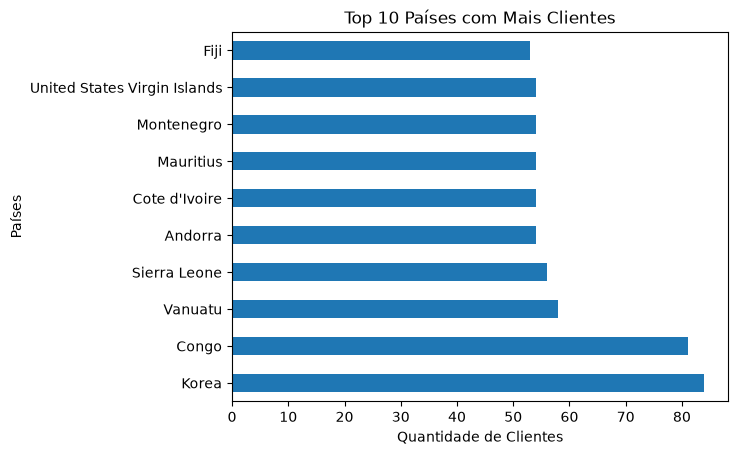

In [5]:
top_10_paises.plot(kind="barh")

plt.title("Top 10 Países com Mais Clientes")
plt.xlabel("Quantidade de Clientes")
plt.ylabel("Países")

plt.show()

In [7]:
# País com mais clientes
paises = df["Country"].value_counts()

# Cidade com mais clientes
cidades = df["City"].value_counts()

print("País com mais clientes:")
print(paises.head(1))

print("\nCidade com mais clientes:")
print(cidades.head(1))

País com mais clientes:
Country
Korea    84
Name: count, dtype: int64

Cidade com mais clientes:
City
Port Marilyn    4
Name: count, dtype: int64


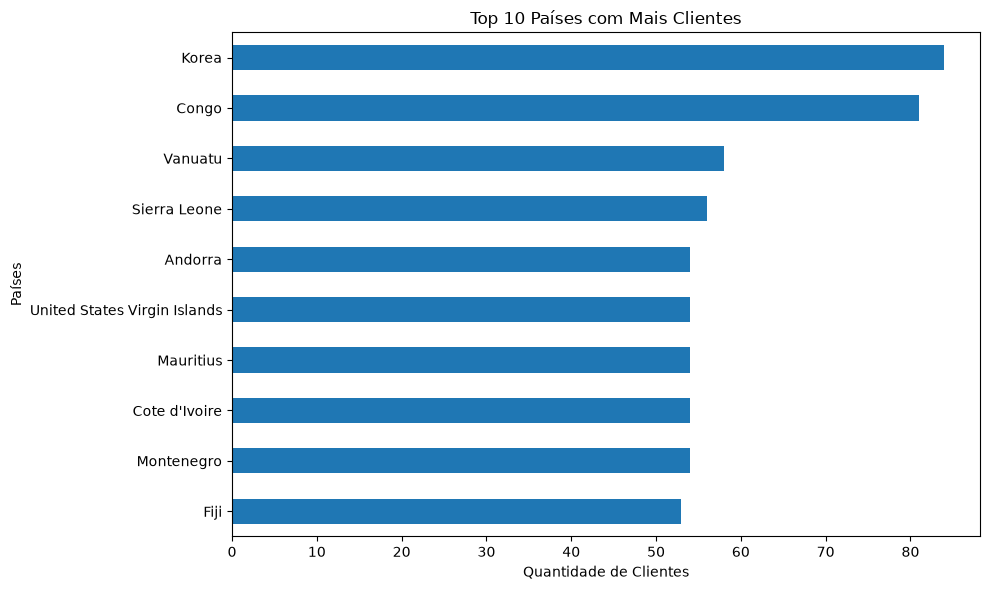

In [8]:
top_10_paises = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 6))

top_10_paises.sort_values().plot(kind="barh")

plt.title("Top 10 Países com Mais Clientes")
plt.xlabel("Quantidade de Clientes")
plt.ylabel("Países")

plt.tight_layout()
plt.show()

#QUESTÃO 2

In [10]:
top_5_cidades = df["City"].value_counts().head(5)

print(top_5_cidades)

City
Port Marilyn      4
Henrymouth        4
Eileenmouth       4
Port Jim          4
Port Catherine    4
Name: count, dtype: int64


In [12]:
#Questão 2 — Datas de Maior Venda
print(df["Subscription Date"].head(10))

0    2020-08-26
1    2020-04-27
2    2022-03-22
3    2020-07-02
4    2021-01-17
5    2021-08-13
6    2020-04-09
7    2021-04-02
8    2020-11-26
9    2021-06-29
Name: Subscription Date, dtype: str


In [15]:
df["Subscription Date"] = pd.to_datetime(
    df["Subscription Date"],
    format="%Y-%m-%d"
)

print(df["Subscription Date"].dtype)

df["Ano"] = df["Subscription Date"].dt.year

vendas_por_ano = df["Ano"].value_counts().sort_index()

print(vendas_por_ano)

print("Ano com mais assinaturas:")
print(vendas_por_ano.idxmax())

print("Quantidade de assinaturas:")
print(vendas_por_ano.max())

datetime64[us]
Ano
2020    4212
2021    4125
2022    1663
Name: count, dtype: int64
Ano com mais assinaturas:
2020
Quantidade de assinaturas:
4212


In [16]:
df["Mes"] = df["Subscription Date"].dt.month

vendas_por_mes = df["Mes"].value_counts().sort_index()

print(vendas_por_mes)

Mes
1     1060
2      931
3     1076
4      989
5      978
6      666
7      691
8      766
9      656
10     717
11     723
12     747
Name: count, dtype: int64


In [17]:
print("Mês com mais assinaturas:")
print(vendas_por_mes.idxmax())

print("Quantidade de assinaturas:")
print(vendas_por_mes.max())

Mês com mais assinaturas:
3
Quantidade de assinaturas:
1076


In [18]:
vendas_mensais = df.groupby(
    df["Subscription Date"].dt.to_period("M")
).size()

print(vendas_mensais)

Subscription Date
2020-01    338
2020-02    325
2020-03    351
2020-04    352
2020-05    347
2020-06    331
2020-07    358
2020-08    383
2020-09    322
2020-10    362
2020-11    373
2020-12    370
2021-01    367
2021-02    284
2021-03    384
2021-04    306
2021-05    317
2021-06    335
2021-07    333
2021-08    383
2021-09    334
2021-10    355
2021-11    350
2021-12    377
2022-01    355
2022-02    322
2022-03    341
2022-04    331
2022-05    314
Freq: M, dtype: int64


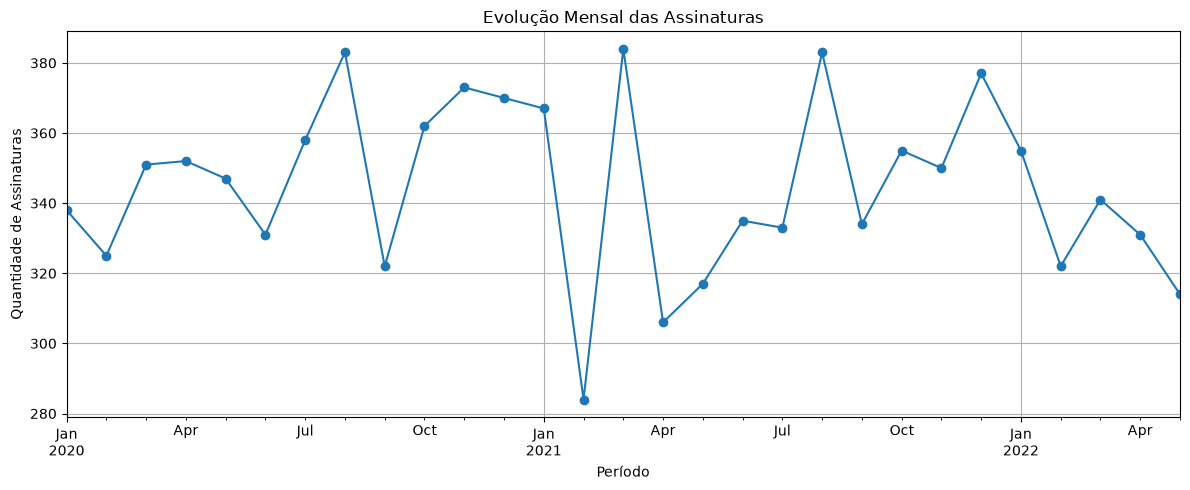

Primeira assinatura: 2020-01-01 00:00:00
Última assinatura: 2022-05-29 00:00:00


In [20]:
plt.figure(figsize=(12, 5))

vendas_mensais.plot(kind="line", marker="o")

plt.title("Evolução Mensal das Assinaturas")
plt.xlabel("Período")
plt.ylabel("Quantidade de Assinaturas")

plt.grid(True)
plt.tight_layout()
plt.show()

print("Primeira assinatura:", df["Subscription Date"].min())
print("Última assinatura:", df["Subscription Date"].max())

#QUESTÃO 3

In [21]:
print("Os 5 meses com mais assinaturas:")

print(vendas_mensais.sort_values(ascending=False).head(5))

Os 5 meses com mais assinaturas:
Subscription Date
2021-03    384
2021-08    383
2020-08    383
2021-12    377
2020-11    373
Freq: M, dtype: int64


In [22]:
#Questão 3: O Maior Cliente B2B

empresas = df["Company"].value_counts()

print(empresas.head(5))

Company
Keith Inc       4
Mosley Group    4
Lucero Ltd      4
Lyons Group     4
Hickman LLC     4
Name: count, dtype: int64


In [23]:
print("Empresa com mais assinaturas:")
print(empresas.idxmax())

print("Quantidade de assinaturas:")
print(empresas.max())

Empresa com mais assinaturas:
Keith Inc
Quantidade de assinaturas:
4


In [26]:
top_5_empresas = df["Company"].value_counts().head(5)

print(top_5_empresas)

print()

maior_quantidade = empresas.max()

empresas_lideres = empresas[empresas == maior_quantidade]

print(empresas_lideres)

Company
Keith Inc       4
Mosley Group    4
Lucero Ltd      4
Lyons Group     4
Hickman LLC     4
Name: count, dtype: int64

Company
Keith Inc          4
Mosley Group       4
Lucero Ltd         4
Lyons Group        4
Hickman LLC        4
Ball and Sons      4
Simon LLC          4
Heath and Sons     4
Ross PLC           4
Dominguez Group    4
Franco PLC         4
Watson Ltd         4
Perry LLC          4
Kemp Ltd           4
Sims PLC           4
Name: count, dtype: int64


#CONCLUSÃO QUESTÃO 3

A análise dos clientes corporativos identificou que Keith Inc, Mosley Group, Lucero Ltd, Lyons Group e Hickman LLC estão entre as empresas com maior número de assinaturas, apresentando 4 registros cada. Entretanto, foi identificado um empate entre 15 organizações, todas com a mesma quantidade de assinaturas. Esse resultado demonstra que não existe uma única empresa dominante na base analisada. Dessa forma, recomenda-se desenvolver estratégias de fidelização e oferecer condições especiais para clientes corporativos, buscando ampliar o número de assinaturas por organização.